# Sadaf Fatima Syeda
## DATA 266 - Homework 1


In [1]:
import random
import numpy as np
import torch
import tensorflow as tf
SID4         = 2733 # last four digits of your SJSU ID
SEED         = 2733      # torch.manual_seed, np.random.seed, random_state
SLICE        = SID4 % 1000   # start index of your dataset subset
HP_ID        = SID4 % 6      # your assigned hyperparameter arm, Table 0.1
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
tf.random.set_seed(SEED)
print("SID4 =", SID4)
print("SEED =", SEED)
print("SLICE =", SLICE)
print("HP_ID =", HP_ID)
print("CLS_A =", CLS_A)
print("CLS_B =", CLS_B)

SID4 = 2733
SEED = 2733
SLICE = 733
HP_ID = 3
CLS_A = 3
CLS_B = 7


1.An autoregressive model predicts the next item ina  sequence using the items that came before it.Autoregressive models are useful because they can learn patterns that occur over time or in a particular order. However, generation can be slow because items are produced one at a time, and an incorrect prediction may affect laterpredictions.Some pf the examples inlcude :

1)A language model predicting the next word from the words already written.
2) A weather model predicting tomorrow's temperature from earlier temperatures.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving diabetes.csv to diabetes.csv


### 2.

In [3]:
import pandas as pd

column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigree",
    "Age",
    "Outcome"
]

df = pd.read_csv("diabetes.csv", header=None, names=column_names)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,-0.294118,0.487437,0.180328,-0.292929,0.000000,0.001490,-0.531170,-0.033333,0
1,-0.882353,-0.145729,0.081967,-0.414141,0.000000,-0.207153,-0.766866,-0.666667,1
2,-0.058824,0.839196,0.049180,0.000000,0.000000,-0.305514,-0.492741,-0.633333,0
3,-0.882353,-0.105528,0.081967,-0.535354,-0.777778,-0.162444,-0.923997,0.000000,1
4,0.000000,0.376884,-0.344262,-0.292929,-0.602837,0.284650,0.887276,-0.600000,0


### 3.

In [4]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nOutcome counts:")
print(df["Outcome"].value_counts())

df.describe()

Dataset shape: (759, 9)
Missing values: 0
Duplicate rows: 0

Outcome counts:
Outcome
1    496
0    263
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
count,759.000000,759.000000,759.000000,759.000000,759.000000,759.000000,759.000000,759.000000,759.000000
mean,-0.407657,0.218563,0.176505,-0.289735,-0.323534,-0.032245,-0.663253,-0.516162,0.653491
std,0.386260,0.306419,0.201287,0.258480,0.375544,0.205376,0.283056,0.400794,0.476171
min,-0.882353,-0.557789,-0.606557,-0.858586,-0.966903,-0.457526,-0.994876,-0.966667,0.000000
25%,-0.764706,-0.005025,0.016393,-0.494949,-0.716312,-0.178837,-0.858241,-0.866667,0.000000
50%,-0.529412,0.165829,0.180328,-0.292929,0.000000,-0.034277,-0.747225,-0.633333,1.000000
75%,0.000000,0.407035,0.311475,0.000000,0.000000,0.087929,-0.531597,-0.233333,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


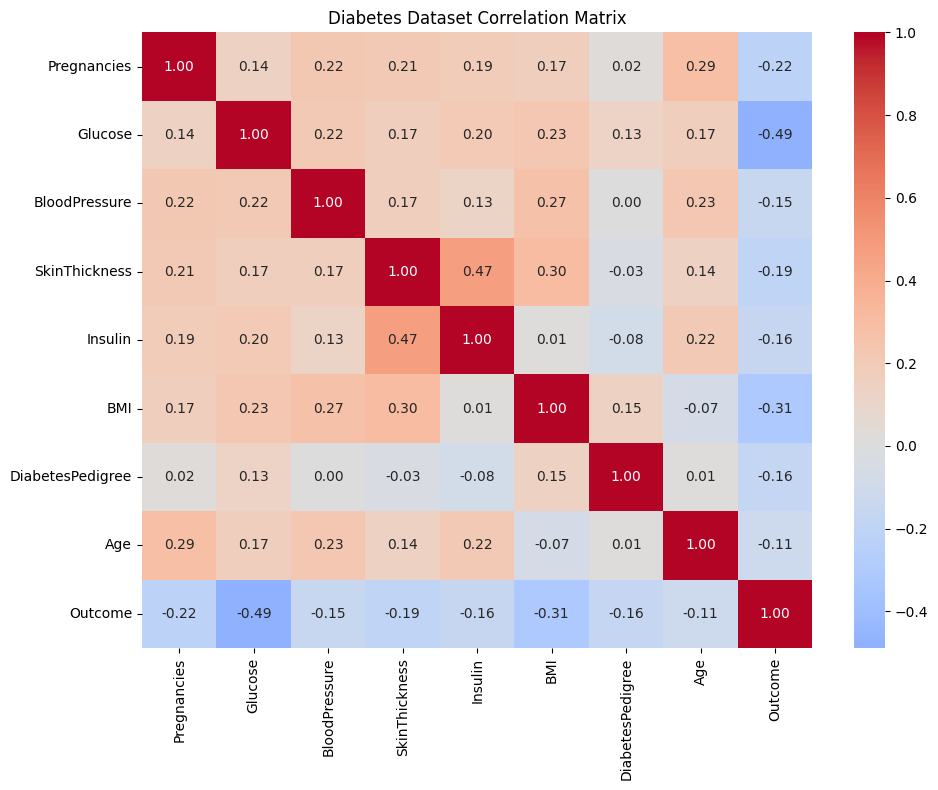

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Diabetes Dataset Correlation Matrix")
plt.tight_layout()
plt.show()

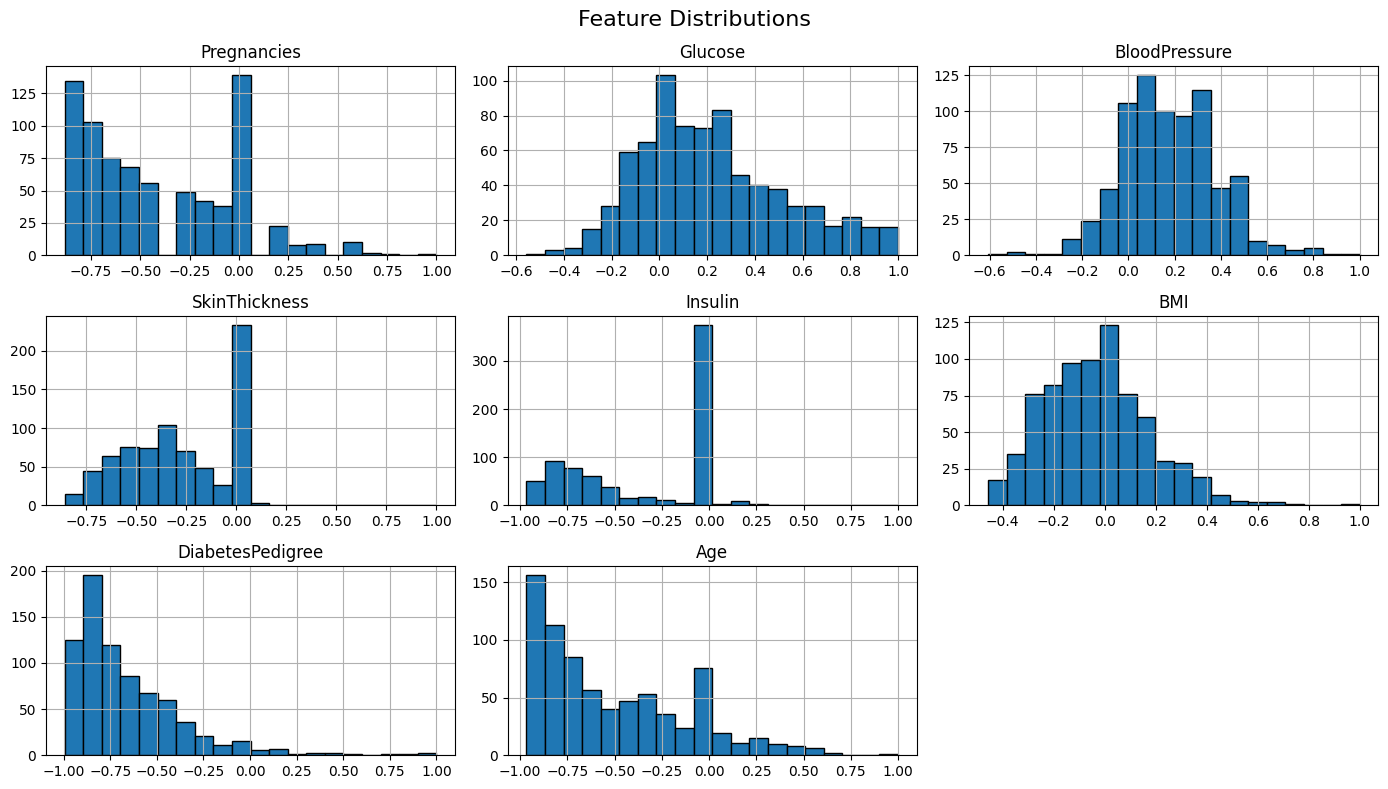

In [6]:
feature_columns = column_names[:-1]

df[feature_columns].hist(
    bins=20,
    figsize=(14, 8),
    edgecolor="black"
)

plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split


X = df.drop(columns=["Outcome"])


y = df["Outcome"]


X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Testing examples:", len(X_test))
print("Total examples:", len(X_train) + len(X_val) + len(X_test))

Training examples: 531
Validation examples: 114
Testing examples: 114
Total examples: 759


In [9]:
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_val.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

y_train_np = y_train.to_numpy(dtype=np.float32).reshape(-1, 1)
y_val_np = y_val.to_numpy(dtype=np.float32).reshape(-1, 1)
y_test_np = y_test.to_numpy(dtype=np.float32).reshape(-1, 1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", device)


class PyTorchNetwork(nn.Module):
    def __init__(self, hidden_layers):
        super().__init__()

        layers = []
        input_size = X_train_np.shape[1]

        for hidden_size in hidden_layers:
            layers.append(nn.Linear(input_size, hidden_size))
            layers.append(nn.ReLU())
            input_size = hidden_size

        layers.append(nn.Linear(input_size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def train_pytorch_model(training_seed, learning_rate, epochs=30):
    random.seed(training_seed)
    np.random.seed(training_seed)
    torch.manual_seed(training_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(training_seed)

    model = PyTorchNetwork([64, 32]).to(device)
    loss_function = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_dataset = TensorDataset(
        torch.tensor(X_train_np),
        torch.tensor(y_train_np)
    )

    generator = torch.Generator()
    generator.manual_seed(training_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    X_val_tensor = torch.tensor(X_val_np).to(device)
    y_val_tensor = torch.tensor(y_val_np).to(device)

    training_losses = []
    validation_losses = []

    for epoch in range(epochs):
        model.train()
        total_training_loss = 0.0

        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            logits = model(batch_X)
            loss = loss_function(logits, batch_y)

            loss.backward()
            optimizer.step()

            total_training_loss += loss.item() * len(batch_X)

        average_training_loss = (
            total_training_loss / len(train_dataset)
        )

        training_losses.append(average_training_loss)

        model.eval()

        with torch.no_grad():
            validation_logits = model(X_val_tensor)

            validation_loss = loss_function(
                validation_logits,
                y_val_tensor
            ).item()

        validation_losses.append(validation_loss)

    model.eval()

    with torch.no_grad():
        X_test_tensor = torch.tensor(X_test_np).to(device)
        test_logits = model(X_test_tensor)
        test_probabilities = torch.sigmoid(test_logits)

        test_predictions = (
            test_probabilities >= 0.5
        ).cpu().numpy().astype(int)

    test_accuracy = np.mean(
        test_predictions == y_test_np.astype(int)
    )

    history = {
        "training_loss": training_losses,
        "validation_loss": validation_losses
    }

    return model, history, test_accuracy


training_seeds = [SEED, SEED + 1, SEED + 2]

pytorch_results = {
    "Baseline": [],
    "Modified": []
}

pytorch_histories = {}

for model_name, learning_rate in [
    ("Baseline", 0.001),
    ("Modified", 0.0003)
]:
    print(f"\nTraining PyTorch {model_name} model")

    for training_seed in training_seeds:
        model, history, accuracy = train_pytorch_model(
            training_seed=training_seed,
            learning_rate=learning_rate,
            epochs=30
        )

        pytorch_results[model_name].append(accuracy)

        if training_seed == SEED:
            pytorch_histories[model_name] = history

        print(
            f"Seed {training_seed}: "
            f"test accuracy = {accuracy:.4f}"
        )


for model_name, accuracies in pytorch_results.items():
    mean_accuracy = np.mean(accuracies)
    standard_deviation = np.std(accuracies, ddof=1)

    print(
        f"\nPyTorch {model_name}: "
        f"mean = {mean_accuracy:.4f}, "
        f"sample SD = {standard_deviation:.4f}"
    )

PyTorch device: cpu

Training PyTorch Baseline model
Seed 2733: test accuracy = 0.7544
Seed 2734: test accuracy = 0.7456
Seed 2735: test accuracy = 0.7368

Training PyTorch Modified model
Seed 2733: test accuracy = 0.7719
Seed 2734: test accuracy = 0.7719
Seed 2735: test accuracy = 0.7632

PyTorch Baseline: mean = 0.7456, sample SD = 0.0088

PyTorch Modified: mean = 0.7690, sample SD = 0.0051


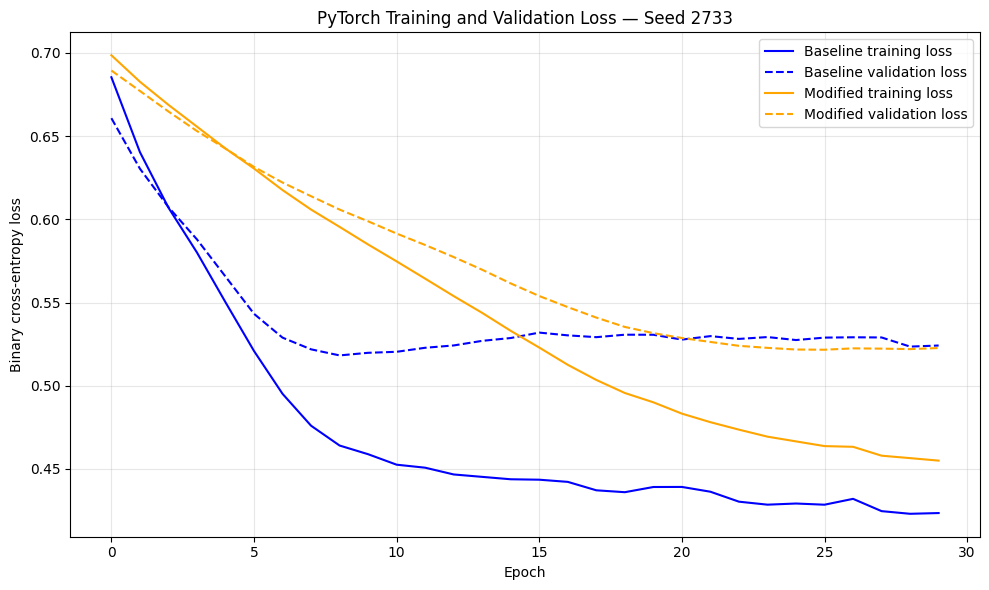

In [10]:
plt.figure(figsize=(10, 6))

plt.plot(
    pytorch_histories["Baseline"]["training_loss"],
    label="Baseline training loss",
    color="blue"
)

plt.plot(
    pytorch_histories["Baseline"]["validation_loss"],
    label="Baseline validation loss",
    color="blue",
    linestyle="--"
)

plt.plot(
    pytorch_histories["Modified"]["training_loss"],
    label="Modified training loss",
    color="orange"
)

plt.plot(
    pytorch_histories["Modified"]["validation_loss"],
    label="Modified validation loss",
    color="orange",
    linestyle="--"
)

plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("PyTorch Training and Validation Loss — Seed 2733")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:

def build_tensorflow_model(learning_rate):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(X_train_np.shape[1],)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


def train_tensorflow_model(
    training_seed,
    learning_rate,
    epochs=30
):
    tf.keras.backend.clear_session()

    random.seed(training_seed)
    np.random.seed(training_seed)
    tf.keras.utils.set_random_seed(training_seed)

    model = build_tensorflow_model(learning_rate)

    history = model.fit(
        X_train_np,
        y_train_np,
        validation_data=(X_val_np, y_val_np),
        epochs=epochs,
        batch_size=32,
        shuffle=True,
        verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test_np,
        y_test_np,
        verbose=0
    )

    return model, history.history, test_accuracy


tensorflow_results = {
    "Baseline": [],
    "Modified": []
}

tensorflow_histories = {}

for model_name, learning_rate in [
    ("Baseline", 0.001),
    ("Modified", 0.0003)
]:
    print(f"\nTraining TensorFlow {model_name} model")

    for training_seed in training_seeds:
        tf_model, tf_history, accuracy = (
            train_tensorflow_model(
                training_seed=training_seed,
                learning_rate=learning_rate,
                epochs=30
            )
        )

        tensorflow_results[model_name].append(accuracy)

        if training_seed == SEED:
            tensorflow_histories[model_name] = tf_history

        print(
            f"Seed {training_seed}: "
            f"test accuracy = {accuracy:.4f}"
        )


for model_name, accuracies in tensorflow_results.items():
    mean_accuracy = np.mean(accuracies)
    standard_deviation = np.std(accuracies, ddof=1)

    print(
        f"\nTensorFlow {model_name}: "
        f"mean = {mean_accuracy:.4f}, "
        f"sample SD = {standard_deviation:.4f}"
    )



Training TensorFlow Baseline model
Seed 2733: test accuracy = 0.7456
Seed 2734: test accuracy = 0.7456
Seed 2735: test accuracy = 0.7281

Training TensorFlow Modified model
Seed 2733: test accuracy = 0.7632
Seed 2734: test accuracy = 0.7719
Seed 2735: test accuracy = 0.7632

TensorFlow Baseline: mean = 0.7398, sample SD = 0.0101

TensorFlow Modified: mean = 0.7661, sample SD = 0.0051


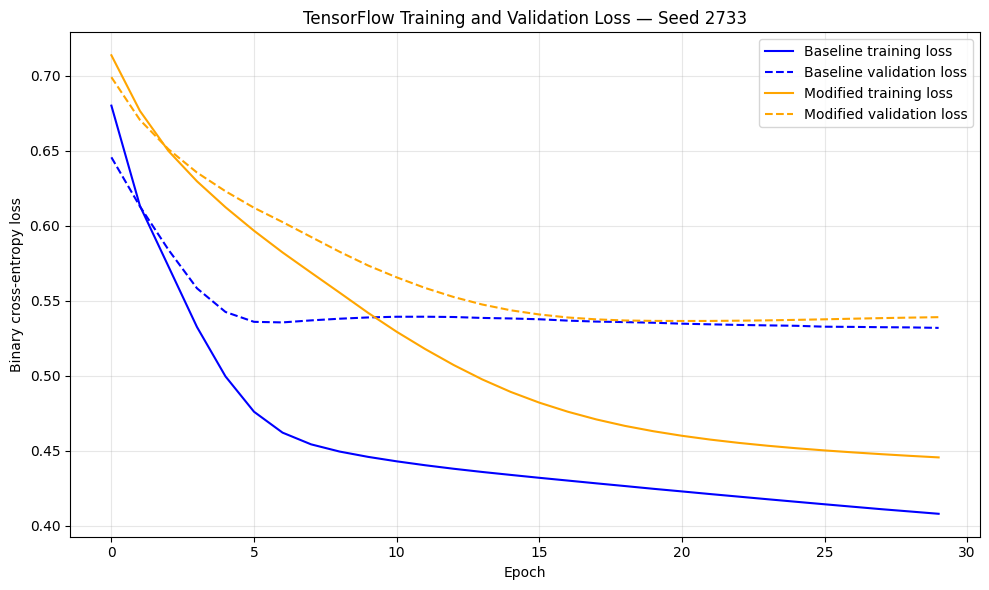

In [13]:
plt.figure(figsize=(10, 6))

plt.plot(
    tensorflow_histories["Baseline"]["loss"],
    label="Baseline training loss",
    color="blue"
)

plt.plot(
    tensorflow_histories["Baseline"]["val_loss"],
    label="Baseline validation loss",
    color="blue",
    linestyle="--"
)

plt.plot(
    tensorflow_histories["Modified"]["loss"],
    label="Modified training loss",
    color="orange"
)

plt.plot(
    tensorflow_histories["Modified"]["val_loss"],
    label="Modified validation loss",
    color="orange",
    linestyle="--"
)

plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("TensorFlow Training and Validation Loss — Seed 2733")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
results_rows = []

for framework, results in [
    ("PyTorch", pytorch_results),
    ("TensorFlow", tensorflow_results)
]:
    for model_name, accuracies in results.items():
        results_rows.append({
            "Framework": framework,
            "Model": model_name,
            "Seed 2733": accuracies[0],
            "Seed 2734": accuracies[1],
            "Seed 2735": accuracies[2],
            "Mean accuracy": np.mean(accuracies),
            "Sample SD": np.std(accuracies, ddof=1)
        })

results_table = pd.DataFrame(results_rows)

display(
    results_table.style.format({
        "Seed 2733": "{:.4f}",
        "Seed 2734": "{:.4f}",
        "Seed 2735": "{:.4f}",
        "Mean accuracy": "{:.4f}",
        "Sample SD": "{:.4f}"
    })
)

,Framework,Model,Seed 2733,Seed 2734,Seed 2735,Mean accuracy,Sample SD
0,PyTorch,Baseline,0.7544,0.7456,0.7368,0.7456,0.0088
1,PyTorch,Modified,0.7719,0.7719,0.7632,0.7690,0.0051
2,TensorFlow,Baseline,0.7456,0.7456,0.7281,0.7398,0.0101
3,TensorFlow,Modified,0.7632,0.7719,0.7632,0.7661,0.0051


In [15]:
for model_name in ["Baseline", "Modified"]:
    pt_train = pytorch_histories[model_name]["training_loss"]
    pt_val = pytorch_histories[model_name]["validation_loss"]

    print(f"PyTorch {model_name}")
    print(f"  Final training loss: {pt_train[-1]:.4f}")
    print(f"  Final validation loss: {pt_val[-1]:.4f}")
    print(f"  Lowest validation loss: {min(pt_val):.4f}")
    print(f"  Lowest validation-loss epoch: {np.argmin(pt_val) + 1}")

for model_name in ["Baseline", "Modified"]:
    tf_train = tensorflow_histories[model_name]["loss"]
    tf_val = tensorflow_histories[model_name]["val_loss"]

    print(f"TensorFlow {model_name}")
    print(f"  Final training loss: {tf_train[-1]:.4f}")
    print(f"  Final validation loss: {tf_val[-1]:.4f}")
    print(f"  Lowest validation loss: {min(tf_val):.4f}")
    print(f"  Lowest validation-loss epoch: {np.argmin(tf_val) + 1}")

PyTorch Baseline
  Final training loss: 0.4235
  Final validation loss: 0.5242
  Lowest validation loss: 0.5182
  Lowest validation-loss epoch: 9
PyTorch Modified
  Final training loss: 0.4550
  Final validation loss: 0.5227
  Lowest validation loss: 0.5217
  Lowest validation-loss epoch: 26
TensorFlow Baseline
  Final training loss: 0.4079
  Final validation loss: 0.5319
  Lowest validation loss: 0.5319
  Lowest validation-loss epoch: 30
TensorFlow Modified
  Final training loss: 0.4455
  Final validation loss: 0.5390
  Lowest validation loss: 0.5365
  Lowest validation-loss epoch: 21


My HP_ID was 3 so I changed the learning rate from 0.001 to 0.0003 while
keeping the [64, 32] layers and 30 epochs unchanged.

The modified model performed better in both frameworks. PyTorch accuracy
increased from 74.56% to 76.90%, while TensorFlow accuracy increased from
73.98% to 76.61%. The modified results also varied less across the three seeds.

The lower learning rate caused slower and more gradual training. The curves
showed mild overfitting in some runs, but the modified models had better average
test accuracy overall. Therefore, the lower learning rate was beneficial in
this experiment.
